# ECOv003 JET Accuracy Analysis with ECOv002 Cal-Val and SOBOL Sensitivity

This notebook performs accuracy assessment, Monte Carlo sensitivity analysis, and Sobol sensitivity analysis of the JET ensemble using ECOSTRESS Collection 2 Cal-Val data.

## Import Required Libraries and Functions

This cell imports all necessary libraries and functions for data processing, model execution, statistical analysis, plotting, and sensitivity analyses (Monte Carlo and Sobol).

In [8]:
import sys
import os
sys.path.insert(0, os.path.abspath(os.path.join(os.path.dirname('__file__'), '..')))
from typing import Callable
from os import makedirs
from os.path import join

import numpy as np
import pandas as pd
from scipy.stats import mstats
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from sklearn.metrics import r2_score, mean_squared_error

# Custom JET and Net Radiation modules
from verma_net_radiation import verma_net_radiation_table
from JET3 import process_JET_table, load_ECOv002_calval_JET_inputs

# Monte Carlo Sensitivity analysis imports
from monte_carlo_sensitivity import (
    perturbed_run, 
    sensitivity_analysis, 
    divide_absolute_by_unperturbed, 
    sensitivity_magnitude_barchart
)

# Sobol analysis imports
from SALib.sample import saltelli
from SALib.analyze import sobol

## Configuration Options & Model Setup

Set configuration options for the notebook, variables, and physical bounds.

In [9]:
# Configuration: Set to True to save plots to files, False to only display them
SAVE_PLOTS = False

input_variables = [
    'ST_C', 'NDVI', 'albedo', 'Ta_C', 'RH', 
    'AOT', 'COT', 'vapor_gccm', 'ozone_cm', 
    'elevation_m', 'canopy_height_meters'
]

output_variables = [
    'Rn_Wm2',
    'ET_daylight_kg',
    'GPP_inst_g_m2_s'
]

# Per-variable physical bounds to keep perturbations realistic
input_min = {
    'ST_C': 0.0, 'NDVI': 0.05, 'albedo': 0.0, 'Ta_C': 0.0,
    'RH': 0.0, 'AOT': 0.0, 'COT': 0.0, 'vapor_gccm': 0.0,
    'ozone_cm': 0.0, 'elevation_m': 0.0, 'canopy_height_meters': 0.0,
}

input_max = {
    'ST_C': 50.0,
    'NDVI': 1,
    'albedo': 1,
}

forward_process = process_JET_table
model_name = 'JET'
normalization_function = divide_absolute_by_unperturbed

## Load, Filter, and Process Data

Loads the ECOSTRESS Cal-Val inputs, applies bounds, and runs the baseline model.

In [10]:
input_df = load_ECOv002_calval_JET_inputs()

# Apply lower and upper bounds from configuration dictionaries
mask = pd.Series(True, index=input_df.index)
for var, min_val in input_min.items():
    if var in input_df.columns:
        mask &= input_df[var] >= min_val
for var, max_val in input_max.items():
    if var in input_df.columns:
        mask &= input_df[var] <= max_val

input_df = input_df[mask]
input_df = input_df.dropna()

# Process baseline data through the model
processed = forward_process(input_df)
processed.head()

[2026-11-20 15:33:10 INFO] starting JET table processing
[2026-11-20 15:33:10 INFO] started extracting geometry from JET input table
[2026-11-20 15:33:10 INFO] completed extracting geometry from JET input table (0.002 seconds)
[2026-11-20 15:33:10 INFO] started extracting time from JET input table
[2026-11-20 15:33:10 INFO] completed extracting time from JET input table (0.001 seconds)
[2026-11-20 15:33:10 INFO] running Forest Light Environmental Simulator
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step
[2026-11-20 15:33:11 INFO] completed processing FLiES-ANN in 0.18 seconds
[2026-11-20 15:33:11 INFO] variable PAR_albedo min: 0.007 mean: 0.055 max: 0.193 nan: 0.00% (nan)
[2026-11-20 15:33:11 INFO] variable NIR_albedo min: 0.066 mean: 0.162 max: 0.530 nan: 0.00% (nan)
[2026-11-20 15:33:11 INFO] variable PAR_direct_Wm2 min: 7.148 mean: 269.735 max: 442.463 nan: 0.00% (nan)
[2026-11-20 15:33:11 INFO] variable SWin_FLiES_ANN min: 163.676 mean: 716.916 max: 1095.605 nan: 0.00% (nan)
[2026-11-20 15:3

/Users/halverso/.local/share/mamba/envs/JET3/lib/python3.13/site-packages/solar_apparent_time/solar_apparent_time.py:37: UserWarning: no explicit representation of timezones available for np.datetime64
  return np.array(arr, dtype='datetime64[ns]')
/Users/halverso/.local/share/mamba/envs/JET3/lib/python3.13/site-packages/solar_apparent_time/solar_apparent_time.py:212: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  doy_UTC = ((times_b.astype('datetime64[D]') - year_start.astype('datetime64[D]')) + 1).astype(int)
/Users/halverso/.local/share/mamba/envs/JET3/lib/python3.13/site-packages/solar_apparent_time/solar_apparent_time.py:37: UserWarning: no explicit representation of timezones available for np.datetime64
  return np.array(arr, dtype='datetime64[ns]')
/Users/halverso/.local/share/mamba/envs/JET3/lib/python3.13/site-

[2026-11-20 15:33:11 INFO] variable gamma min: 44.648 mean: 58.961 max: 68.139 nan: 0.00% (nan)
[2026-11-20 15:33:11 INFO] variable Cp min: 1006.679 mean: 1012.269 max: 1019.788 nan: 0.00% (nan)
[2026-11-20 15:33:11 INFO] variable rhoa min: 0.776 mean: 1.045 max: 1.231 nan: 0.00% (nan)
[2026-11-20 15:33:11 INFO] variable epsa min: 0.679 mean: 0.765 max: 0.966 nan: 0.00% (nan)
[2026-11-20 15:33:11 INFO] variable R min: 14.018 mean: 108.103 max: 1000.000 nan: 0.00% (nan)
[2026-11-20 15:33:11 INFO] variable Rc min: 14.018 mean: 108.103 max: 1000.000 nan: 0.00% (nan)
[2026-11-20 15:33:11 INFO] variable Rs min: 7.009 mean: 54.052 max: 500.000 nan: 0.00% (nan)
[2026-11-20 15:33:11 INFO] variable SFd min: 0.020 mean: 0.051 max: 0.077 nan: 0.00% (nan)
[2026-11-20 15:33:11 INFO] variable SFd2 min: 0.172 mean: 0.334 max: 0.983 nan: 0.00% (nan)
[2026-11-20 15:33:11 INFO] variable DL min: 8.245 mean: 11.401 max: 14.086 nan: 0.00% (nan)
[2026-11-20 15:33:11 INFO] variable Ra min: 416.618 mean: 888.

/Users/halverso/.local/share/mamba/envs/JET3/lib/python3.13/site-packages/solar_apparent_time/solar_apparent_time.py:37: UserWarning: no explicit representation of timezones available for np.datetime64
  return np.array(arr, dtype='datetime64[ns]')
/Users/halverso/.local/share/mamba/envs/JET3/lib/python3.13/site-packages/solar_apparent_time/solar_apparent_time.py:37: UserWarning: no explicit representation of timezones available for np.datetime64
  return np.array(arr, dtype='datetime64[ns]')
/Users/halverso/.local/share/mamba/envs/JET3/lib/python3.13/site-packages/solar_apparent_time/solar_apparent_time.py:212: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  doy_UTC = ((times_b.astype('datetime64[D]') - year_start.astype('datetime64[D]')) + 1).astype(int)
/Users/halverso/.local/share/mamba/envs/JET3/lib/python3.13/site-

,Unnamed: 0,ID,vegetation,climate,STICinst,BESSinst,MOD16inst,PTJPLSMinst,ETinst,ETinstUncertainty,...,G_PMJPL_Wm2,G_Wm2,LE_instantaneous_Wm2,LE_Wm2,H_Wm2,ET_daylight_kg,ET_uncertainty,GPP_inst_g_m2_s,ET_canopy_inst_kg_m2_s,WUE
15,15,US-xAB,ENF,Csb,141.635670,168.24043,402.81810,159.71700,139.016083,107.183200,...,24.219544,24.219544,203.764376,203.764376,248.713696,2.900053,0.510811,0.000151,0.000058,2.606544
17,17,US-xAB,ENF,Csb,1.881266,163.94730,301.40400,179.13661,131.273636,106.525215,...,13.772918,13.772918,163.144742,163.144742,194.438550,2.854526,1.085331,0.000108,0.000034,3.174119
18,18,US-xAB,ENF,Csb,3.135606,246.87700,614.51480,405.50497,366.056641,222.890230,...,33.327171,33.327171,342.565013,342.565013,348.501129,4.442026,0.971980,0.000291,0.000122,2.390822
19,19,US-xAB,ENF,Csb,311.482820,290.73126,672.27510,478.82382,439.821228,153.787670,...,42.878466,42.878466,403.011097,403.011097,366.186555,4.947329,1.401781,0.000294,0.000211,1.388074
20,20,US-xAB,ENF,Csb,51.920338,95.28810,116.67136,73.20884,232.693512,24.038680,...,2.903705,2.903705,112.556235,112.556235,52.720986,2.991218,0.730132,0.000095,0.000015,6.238326


## Accuracy Comparison Analysis

Examining the accuracy of model estimates compared to ground data.

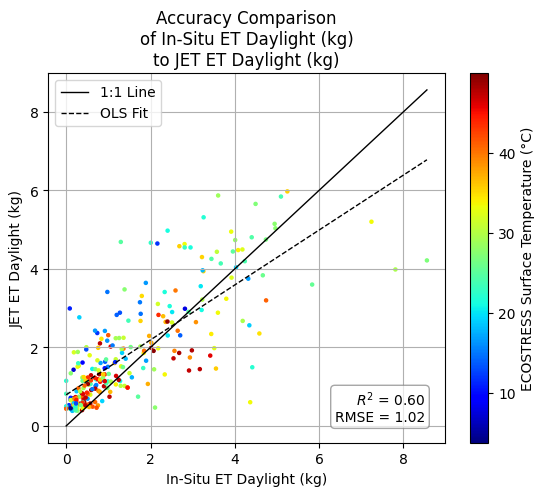

In [11]:
def generate_accuracy_plot(df, x_variable, y_variable, output_variable, model_name, color_col='ST_C', cbar_label='ECOSTRESS Surface Temperature (°C)', save_plots=False):
    """
    Generates and optionally saves a scatter plot comparing in-situ data to model output,
    including a 1:1 line, OLS regression fit, R-squared, and RMSE annotations.
    """
    valid_data = df[[x_variable, y_variable, color_col]].dropna()
    
    # Create the scatter plot
    sc = plt.scatter(
        x=valid_data[x_variable],
        y=valid_data[y_variable],
        c=valid_data[color_col],
        cmap='jet',
        s=5
    )

    # Get the actual data bounds to ensure lines span the whole plot
    x_min, x_max = valid_data[x_variable].min(), valid_data[x_variable].max()
    y_min, y_max = valid_data[y_variable].min(), valid_data[y_variable].max()
    
    # Calculate a square bounding box for the 1:1 line
    plot_min = min(x_min, y_min)
    plot_max = max(x_max, y_max)

    plt.plot([plot_min, plot_max], [plot_min, plot_max], color='black', linestyle='-', linewidth=1, label='1:1 Line')

    # Add OLS regression line
    coefs = np.polyfit(valid_data[x_variable], valid_data[y_variable], 1)
    ols_x = np.array([x_min, x_max])
    ols_y = coefs[0] * ols_x + coefs[1]
    plt.plot(ols_x, ols_y, color='black', linestyle='--', linewidth=1, label='OLS Fit')

    # R-squared of the linear fit
    y_true_for_r2 = valid_data[y_variable]
    y_pred_from_ols = coefs[0] * valid_data[x_variable] + coefs[1]
    r2 = r2_score(y_true_for_r2, y_pred_from_ols)
    
    # RMSE between the model and in-situ data
    rmse = np.sqrt(mean_squared_error(valid_data[x_variable], valid_data[y_variable]))

    # Annotate R-squared and RMSE on plot in lower right corner
    plt.annotate(f"$R^2$ = {r2:.2f}\nRMSE = {rmse:.2f}",
                xy=(0.95, 0.05), xycoords='axes fraction',
                ha='right', va='bottom',
                fontsize=10,
                bbox=dict(boxstyle='round', fc='white', ec='gray', alpha=0.7))

    # Format the plot
    plt.grid(True, zorder=0)
    plt.xlabel(f"In-Situ {output_variable}")
    plt.ylabel(f"{model_name} {output_variable}")
    plt.title(f"Accuracy Comparison\nof In-Situ {output_variable}\nto {model_name} {output_variable}")
    
    plt.colorbar(sc, label=cbar_label)
    plt.legend(loc='upper left')
    
    # Save if requested
    if save_plots:
        plt.savefig(f"Accuracy Comparison of In-Situ {output_variable} to {model_name} {output_variable}.jpeg", format='jpeg', bbox_inches='tight')
        plt.savefig(f"Accuracy Comparison of In-Situ {output_variable} to {model_name} {output_variable}.svg", format='svg', bbox_inches='tight')
    
    plt.show()

# Execute Example for ET
generate_accuracy_plot(
    df=processed, 
    x_variable='insitu_ET_daylight_kg', # Replace with exact column name if different
    y_variable='ET_daylight_kg', 
    output_variable='ET Daylight (kg)', 
    model_name=model_name,
    save_plots=SAVE_PLOTS
)

## Monte Carlo Sensitivity Analysis

Utilizes the pre-imported `monte_carlo_sensitivity` functions.

[2026-11-20 15:33:11 INFO] starting JET table processing
[2026-11-20 15:33:11 INFO] started extracting geometry from JET input table
[2026-11-20 15:33:11 INFO] completed extracting geometry from JET input table (0.002 seconds)
[2026-11-20 15:33:11 INFO] started extracting time from JET input table
[2026-11-20 15:33:11 INFO] completed extracting time from JET input table (0.001 seconds)
[2026-11-20 15:33:11 INFO] running Forest Light Environmental Simulator
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step
[2026-11-20 15:33:11 INFO] completed processing FLiES-ANN in 0.19 seconds
[2026-11-20 15:33:11 INFO] variable PAR_albedo min: 0.007 mean: 0.055 max: 0.193 nan: 0.00% (nan)
[2026-11-20 15:33:11 INFO] variable NIR_albedo min: 0.066 mean: 0.162 max: 0.530 nan: 0.00% (nan)
[2026-11-20 15:33:11 INFO] variable PAR_direct_Wm2 min: 7.148 mean: 269.735 max: 442.463 nan: 0.00% (nan)
[2026-11-20 15:33:11 INFO] variable SWin_FLiES_ANN min: 163.676 mean: 716.916 max: 1095.605 nan: 0.00% (nan)
[2026-11-20 15:3

/Users/halverso/.local/share/mamba/envs/JET3/lib/python3.13/site-packages/solar_apparent_time/solar_apparent_time.py:37: UserWarning: no explicit representation of timezones available for np.datetime64
  return np.array(arr, dtype='datetime64[ns]')
/Users/halverso/.local/share/mamba/envs/JET3/lib/python3.13/site-packages/solar_apparent_time/solar_apparent_time.py:212: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  doy_UTC = ((times_b.astype('datetime64[D]') - year_start.astype('datetime64[D]')) + 1).astype(int)
/Users/halverso/.local/share/mamba/envs/JET3/lib/python3.13/site-packages/solar_apparent_time/solar_apparent_time.py:37: UserWarning: no explicit representation of timezones available for np.datetime64
  return np.array(arr, dtype='datetime64[ns]')
/Users/halverso/.local/share/mamba/envs/JET3/lib/python3.13/site-

[2026-11-20 15:33:11 INFO] variable ball_berry_slope_C4 min: 4.203 mean: 5.177 max: 5.800 nan: 0.00% (nan)
[2026-11-20 15:33:11 INFO] variable ball_berry_intercept_C3 min: 0.005 mean: 0.010 max: 0.015 nan: 0.00% (nan)
[2026-11-20 15:33:11 INFO] variable KG_climate (float32) with [2. 3. 4. 5.] unique values
[2026-11-20 15:33:11 INFO] * 2.0: 154
[2026-11-20 15:33:11 INFO] * 3.0: 28
[2026-11-20 15:33:11 INFO] * 4.0: 86
[2026-11-20 15:33:11 INFO] * 5.0: 2
[2026-11-20 15:33:11 INFO] variable canopy_height_meters min: 0.000 mean: 3.962 max: 25.743 nan: 0.00% (nan)
[2026-11-20 15:33:11 INFO] All GEOS-5 FP inputs provided, no retrieval needed.
[2026-11-20 15:33:11 INFO] variable canopy_temperature_C min: 3.730 mean: 30.458 max: 49.990 nan: 0.00% (nan)
[2026-11-20 15:33:11 INFO] variable soil_temperature_C min: 3.730 mean: 30.458 max: 49.990 nan: 0.00% (nan)
[2026-11-20 15:33:11 INFO] using given FLiES output as BESS parameters
[2026-11-20 15:33:11 INFO] variable Ps_Pa min: 66823.360 mean: 8855

/Users/halverso/.local/share/mamba/envs/JET3/lib/python3.13/site-packages/solar_apparent_time/solar_apparent_time.py:37: UserWarning: no explicit representation of timezones available for np.datetime64
  return np.array(arr, dtype='datetime64[ns]')
/Users/halverso/.local/share/mamba/envs/JET3/lib/python3.13/site-packages/solar_apparent_time/solar_apparent_time.py:37: UserWarning: no explicit representation of timezones available for np.datetime64
  return np.array(arr, dtype='datetime64[ns]')
/Users/halverso/.local/share/mamba/envs/JET3/lib/python3.13/site-packages/solar_apparent_time/solar_apparent_time.py:212: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  doy_UTC = ((times_b.astype('datetime64[D]') - year_start.astype('datetime64[D]')) + 1).astype(int)
/Users/halverso/.local/share/mamba/envs/JET3/lib/python3.13/site-

[2026-11-20 15:33:12 INFO] starting JET table processing
[2026-11-20 15:33:14 INFO] started extracting geometry from JET input table
[2026-11-20 15:33:15 INFO] completed extracting geometry from JET input table (1.038 seconds)
[2026-11-20 15:33:15 INFO] started extracting time from JET input table
[2026-11-20 15:33:16 INFO] completed extracting time from JET input table (0.112 seconds)
[2026-11-20 15:33:16 INFO] running Forest Light Environmental Simulator


/Users/halverso/.local/share/mamba/envs/JET3/lib/python3.13/site-packages/solar_apparent_time/solar_apparent_time.py:37: UserWarning: no explicit representation of timezones available for np.datetime64
  return np.array(arr, dtype='datetime64[ns]')
/Users/halverso/.local/share/mamba/envs/JET3/lib/python3.13/site-packages/solar_apparent_time/solar_apparent_time.py:212: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  doy_UTC = ((times_b.astype('datetime64[D]') - year_start.astype('datetime64[D]')) + 1).astype(int)


... (19 outputs left out)

/Users/halverso/.local/share/mamba/envs/JET3/lib/python3.13/site-packages/solar_apparent_time/solar_apparent_time.py:37: UserWarning: no explicit representation of timezones available for np.datetime64
  return np.array(arr, dtype='datetime64[ns]')
/Users/halverso/.local/share/mamba/envs/JET3/lib/python3.13/site-packages/solar_apparent_time/solar_apparent_time.py:212: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  doy_UTC = ((times_b.astype('datetime64[D]') - year_start.astype('datetime64[D]')) + 1).astype(int)
/Users/halverso/.local/share/mamba/envs/JET3/lib/python3.13/site-packages/solar_apparent_time/solar_apparent_time.py:37: UserWarning: no explicit representation of timezones available for np.datetime64
  return np.array(arr, dtype='datetime64[ns]')
/Users/halverso/.local/share/mamba/envs/JET3/lib/python3.13/site-

[2026-11-20 15:33:39 INFO] completed daylight ET upscaling (PMJPL)
[2026-11-20 15:33:39 INFO] completed processing PM-JPL in 3.83 seconds
[2026-11-20 15:33:40 INFO] variable LE_PMJPL_Wm2 min: 0.000 mean: 97.195 max: 780.303 nan: 1.45% (nan)
[2026-11-20 15:33:40 INFO] variable ET_daylight_PMJPL_kg min: 0.000 mean: 1.362 max: 9.001 nan: 1.45% (nan)
[2026-11-20 15:33:40 INFO] variable G_PMJPL_Wm2 min: 0.000 mean: 68.310 max: 216.180 nan: 1.45% (nan)
[2026-11-20 15:33:40 INFO] variable ET_daylight_kg min: 0.000 mean: 1.839 max: 8.913 nan: 0.00% (nan)


/Users/halverso/.local/share/mamba/envs/JET3/lib/python3.13/site-packages/solar_apparent_time/solar_apparent_time.py:212: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  doy_UTC = ((times_b.astype('datetime64[D]') - year_start.astype('datetime64[D]')) + 1).astype(int)


[2026-11-20 15:33:40 INFO] JET table processing complete (27.878 seconds)


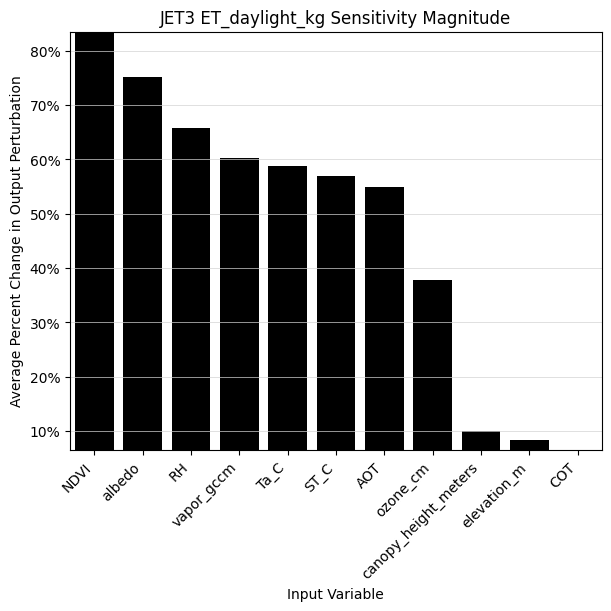

In [12]:
# Unpack the tuple returned by sensitivity_analysis
_, mc_df = sensitivity_analysis(
    input_df=input_df,
    forward_process=forward_process,
    input_variables=input_variables,
    output_variables=output_variables,
    input_min=input_min,
    input_max=input_max,
    normalization_function=normalization_function
)

# Visualize magnitude for a specific target output
sensitivity_magnitude_barchart(
    model_name='JET3',
    output_variable=['ET_daylight_kg'],
    df=mc_df,
    metric=mc_df['metric'].iloc[0]
)

## Sobol Sensitivity Analysis

The Sobol analysis decomposes variance into First-Order (S1) and Total-Order (ST) effects to measure direct and interactive sensitivities.

In [ ]:
# 1. Define the SALib problem dictionary based on configs
problem = {
    'num_vars': len(input_variables),
    'names': input_variables,
    'bounds': [
        [input_min.get(var, 0.0), input_max.get(var, 100.0)] # Uses config bounds, defaults to 100 if no max specified
        for var in input_variables
    ]
}

# 2. Generate Sobol samples
# N=256 generates N * (2D + 2) samples (increase back to 1024 if needed once verified)
param_samples = saltelli.sample(problem, 256)

# 3. Create a vectorized wrapper to map generated SALib parameters to the model's input format
def evaluate_model_for_sobol(params_array, base_df):
    # Filter to valid daytime observations so SZA_deg / time_UTC produce positive SWin
    daytime_df = base_df[base_df['SZA_deg'] < 85].copy() if 'SZA_deg' in base_df.columns else base_df.copy()
    if 'SWin_Wm2' in daytime_df.columns:
        daytime_df = daytime_df[daytime_df['SWin_Wm2'] > 0]

    # Preserve non-numeric columns from a valid daytime row, then overwrite numeric columns with their daytime means
    template_row = daytime_df.iloc[0].to_dict()
    template_row.update(daytime_df.mean(numeric_only=True).to_dict())

    # Broadcast template across all Sobol samples at once
    samples_df = pd.DataFrame([template_row] * len(params_array))
    for idx, var in enumerate(input_variables):
        samples_df[var] = params_array[:, idx]

    # Run JET in one vectorized pass
    out = forward_process(samples_df)
    return out['ET_daylight_kg'].to_numpy()

# 4. Run the model on the generated samples
Y_sobol = evaluate_model_for_sobol(param_samples, input_df)

# 5. Perform the Sobol Analysis
sobol_indices = sobol.analyze(problem, Y_sobol, print_to_console=False)

# 6. Plot the Sobol Results
sobol_df = pd.DataFrame({
    'Variable': input_variables,
    'S1': sobol_indices['S1'],
    'ST': sobol_indices['ST']
}).set_index('Variable').sort_values(by='ST', ascending=False)

sobol_df.plot(kind='bar', figsize=(10, 6))
plt.title("Sobol Sensitivity Indices for JET Ensemble (ET_daylight_kg)")
plt.ylabel("Sensitivity Index")
plt.tight_layout()
if SAVE_PLOTS:
    plt.savefig("Sobol_Sensitivity_Analysis.jpeg", format="jpeg")
plt.show()

[2026-11-20 15:35:22 INFO] starting JET table processing
[2026-11-20 15:35:22 INFO] started extracting geometry from JET input table
[2026-11-20 15:35:22 INFO] completed extracting geometry from JET input table (0.000 seconds)
[2026-11-20 15:35:22 INFO] started extracting time from JET input table
[2026-11-20 15:35:22 INFO] completed extracting time from JET input table (0.000 seconds)
[2026-11-20 15:35:22 INFO] running Forest Light Environmental Simulator
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step
[2026-11-20 15:35:22 INFO] completed processing FLiES-ANN in 0.09 seconds
[2026-11-20 15:35:22 INFO] variable PAR_albedo (float64) with [0.0548141] unique values
[2026-11-20 15:35:22 INFO] * 0.05481410475296783: 1
[2026-11-20 15:35:22 INFO] variable NIR_albedo (float64) with [0.16154517] unique values
[2026-11-20 15:35:22 INFO] * 0.16154517092251694: 1
[2026-11-20 15:35:22 INFO] variable PAR_direct_Wm2 (float32) with [4.977894] unique values
[2026-11-20 15:35:22 INFO] * 4.977894: 1
[2026-11-20 15

/var/folders/hk/35_x93nx79vg1zmd2fy1vcbr0000gq/T/ipykernel_93941/1461747880.py:13: DeprecationWarning: `salib.sample.saltelli` will be removed in SALib 1.5.1 Please use `salib.sample.sobol`
  param_samples = saltelli.sample(problem, 1024)
/Users/halverso/.local/share/mamba/envs/JET3/lib/python3.13/site-packages/solar_apparent_time/solar_apparent_time.py:37: UserWarning: no explicit representation of timezones available for np.datetime64
  return np.array(arr, dtype='datetime64[ns]')
/Users/halverso/.local/share/mamba/envs/JET3/lib/python3.13/site-packages/solar_apparent_time/solar_apparent_time.py:212: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  doy_UTC = ((times_b.astype('datetime64[D]') - year_start.astype('datetime64[D]')) + 1).astype(int)
/Users/halverso/.local/share/mamba/envs/JET3/lib/python3.13/site-packages/s

[2026-11-20 15:35:22 INFO] variable PARin_soil_Wm2 (float64) with [46.77901092] unique values
[2026-11-20 15:35:22 INFO] * 46.77901092283673: 1
[2026-11-20 15:35:22 INFO] variable APAR_Soil (float64) with [39.76215928] unique values
[2026-11-20 15:35:22 INFO] * 39.76215928441122: 1
[2026-11-20 15:35:22 INFO] variable APARout_sunlit_Wm2 (float64) with [5.92305706] unique values
[2026-11-20 15:35:22 INFO] * 5.923057063023663: 1
[2026-11-20 15:35:22 INFO] variable APARout_shade_Wm2 (float64) with [1.09379458] unique values
[2026-11-20 15:35:22 INFO] * 1.0937945754018468: 1
[2026-11-20 15:35:22 INFO] variable APAR_sunlit_Wm2 (float64) with [13.87887592] unique values
[2026-11-20 15:35:22 INFO] * 13.878875917035852: 1
[2026-11-20 15:35:22 INFO] variable APAR_shade_Wm2 (float64) with [1.71231158] unique values
[2026-11-20 15:35:22 INFO] * 1.7123115828717237: 1
[2026-11-20 15:35:22 INFO] variable ANIRin_sunlit_Wm2 (float64) with [2.44575641] unique values
[2026-11-20 15:35:22 INFO] * 2.445756

/Users/halverso/.local/share/mamba/envs/JET3/lib/python3.13/site-packages/solar_apparent_time/solar_apparent_time.py:37: UserWarning: no explicit representation of timezones available for np.datetime64
  return np.array(arr, dtype='datetime64[ns]')
/Users/halverso/.local/share/mamba/envs/JET3/lib/python3.13/site-packages/solar_apparent_time/solar_apparent_time.py:37: UserWarning: no explicit representation of timezones available for np.datetime64
  return np.array(arr, dtype='datetime64[ns]')
/Users/halverso/.local/share/mamba/envs/JET3/lib/python3.13/site-packages/solar_apparent_time/solar_apparent_time.py:212: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  doy_UTC = ((times_b.astype('datetime64[D]') - year_start.astype('datetime64[D]')) + 1).astype(int)
/Users/halverso/.local/share/mamba/envs/JET3/lib/python3.13/site-

[2026-11-20 15:35:22 INFO] completed processing FLiES-ANN in 0.10 seconds
[2026-11-20 15:35:22 INFO] variable PAR_albedo (float64) with [0.0548141] unique values
[2026-11-20 15:35:22 INFO] * 0.05481410475296783: 1
[2026-11-20 15:35:22 INFO] variable NIR_albedo (float64) with [0.16154517] unique values
[2026-11-20 15:35:22 INFO] * 0.16154517092251694: 1
[2026-11-20 15:35:22 INFO] variable PAR_direct_Wm2 (float32) with [4.977894] unique values
[2026-11-20 15:35:22 INFO] * 4.977894: 1
[2026-11-20 15:35:22 INFO] variable SWin_FLiES_ANN (float32) with [154.1644] unique values
[2026-11-20 15:35:22 INFO] * 154.1644: 1
[2026-11-20 15:35:22 INFO] running Breathing Earth System Simulator
<class 'numpy.ndarray'>
float32
[2026-11-20 15:35:22 INFO] variable SZA_deg (float32) with [46.01744] unique values
[2026-11-20 15:35:22 INFO] * 46.01744: 1
[2026-11-20 15:35:22 INFO] variable CI (float64) with [0.26588235] unique values
[2026-11-20 15:35:22 INFO] * 0.2658823529411764: 1
[2026-11-20 15:35:22 INF

/Users/halverso/.local/share/mamba/envs/JET3/lib/python3.13/site-packages/solar_apparent_time/solar_apparent_time.py:37: UserWarning: no explicit representation of timezones available for np.datetime64
  return np.array(arr, dtype='datetime64[ns]')
/Users/halverso/.local/share/mamba/envs/JET3/lib/python3.13/site-packages/solar_apparent_time/solar_apparent_time.py:212: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  doy_UTC = ((times_b.astype('datetime64[D]') - year_start.astype('datetime64[D]')) + 1).astype(int)
/Users/halverso/.local/share/mamba/envs/JET3/lib/python3.13/site-packages/solar_apparent_time/solar_apparent_time.py:37: UserWarning: no explicit representation of timezones available for np.datetime64
  return np.array(arr, dtype='datetime64[ns]')
/Users/halverso/.local/share/mamba/envs/JET3/lib/python3.13/site-

... (29 outputs left out)

/Users/halverso/.local/share/mamba/envs/JET3/lib/python3.13/site-packages/solar_apparent_time/solar_apparent_time.py:37: UserWarning: no explicit representation of timezones available for np.datetime64
  return np.array(arr, dtype='datetime64[ns]')
/Users/halverso/.local/share/mamba/envs/JET3/lib/python3.13/site-packages/solar_apparent_time/solar_apparent_time.py:212: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  doy_UTC = ((times_b.astype('datetime64[D]') - year_start.astype('datetime64[D]')) + 1).astype(int)
/Users/halverso/.local/share/mamba/envs/JET3/lib/python3.13/site-packages/solar_apparent_time/solar_apparent_time.py:37: UserWarning: no explicit representation of timezones available for np.datetime64
  return np.array(arr, dtype='datetime64[ns]')
/Users/halverso/.local/share/mamba/envs/JET3/lib/python3.13/site-

[2026-11-20 15:35:26 INFO] * 0.19648917728716347: 1
[2026-11-20 15:35:26 INFO] variable ET_daylight_kg (float64) with [5.57882268] unique values
[2026-11-20 15:35:26 INFO] * 5.578822677534829: 1
[2026-11-20 15:35:26 INFO] JET table processing complete (0.319 seconds)
[2026-11-20 15:35:26 INFO] starting JET table processing
[2026-11-20 15:35:26 INFO] started extracting geometry from JET input table
[2026-11-20 15:35:26 INFO] completed extracting geometry from JET input table (0.000 seconds)
[2026-11-20 15:35:26 INFO] started extracting time from JET input table
[2026-11-20 15:35:26 INFO] completed extracting time from JET input table (0.000 seconds)
[2026-11-20 15:35:26 INFO] running Forest Light Environmental Simulator
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step
[2026-11-20 15:35:26 INFO] completed processing FLiES-ANN in 0.10 seconds
[2026-11-20 15:35:26 INFO] variable PAR_albedo (float64) with [0.0548141] unique values
[2026-11-20 15:35:26 INFO] * 0.05481410475296783: 1
[2026-11-20 15:35:2

/Users/halverso/.local/share/mamba/envs/JET3/lib/python3.13/site-packages/solar_apparent_time/solar_apparent_time.py:37: UserWarning: no explicit representation of timezones available for np.datetime64
  return np.array(arr, dtype='datetime64[ns]')
/Users/halverso/.local/share/mamba/envs/JET3/lib/python3.13/site-packages/solar_apparent_time/solar_apparent_time.py:212: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  doy_UTC = ((times_b.astype('datetime64[D]') - year_start.astype('datetime64[D]')) + 1).astype(int)


BlankOutput: blank solar radiation output